# Wstępna EDA — artykuły zebrane ze stron (`data/clean`)

**Cel projektu:** zbadać, w jakim stopniu polskie serwisy informacyjne korzystają z AI do (współ)pisania artykułów.

**Zakres tej EDA:** dane ze stron (`data/clean/<rok>/<domena>.jsonl`).



In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path("../../data/clean")
FRAME_DIR = Path("../../data/frame")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


## 1. Wczytanie danych

Skanujemy wyłącznie foldery lat (`^\d{4}$`), ignorując inne nie-roczne foldery (np. cache Common Crawl).

In [2]:
YEAR_DIR_RE = re.compile(r"^\d{4}$")

year_dirs = sorted(p for p in DATA_DIR.iterdir() if p.is_dir() and YEAR_DIR_RE.match(p.name))
print("Znalezione foldery lat:", [p.name for p in year_dirs])


Znalezione foldery lat: ['2020', '2021', '2022', '2023', '2024', '2025']


In [3]:
def load_articles(year_dirs: list[Path]) -> pd.DataFrame:
    rows = []
    for year_dir in year_dirs:
        for jsonl_path in sorted(year_dir.glob("*.jsonl")):
            with jsonl_path.open(encoding="utf-8") as f:
                for line in f:
                    line = line.strip()
                    if not line:
                        continue
                    rec = json.loads(line)
                    rec["collection_year_dir"] = year_dir.name
                    rows.append(rec)
    return pd.DataFrame(rows)


articles = load_articles(year_dirs)
print(f"Wczytano {len(articles)} artykułów z {articles['domain'].nunique()} domen.")
articles.head(3)


Wczytano 5026 artykułów z 44 domen.


,article_id,domain,stratum,url,crawl_id,warc_filename,warc_offset,warc_length,pub_date,pub_year,title,crawl_timestamp,author_present,n_words,languages,text_sha1,text,collection_year_dir
0,e804fd82c414f4da5db268c9611173fb9b8cf13c,demagog.org.pl,S2,https://demagog.org.pl/fake_news/nie-singapur-...,CC-MAIN-2021-04,crawl-data/CC-MAIN-2021-04/segments/1610703529...,284248942,20475,2020-12-15,2020,"Nie, Singapur nie wstrzymał wszystkich szczepień",20210122091715,False,1027,pol,5b6d8e974b5bb302eb284db804f287571feaceb2,"Czas czytania: około\nNie, Singapur nie wstrzy...",2020
1,bad5cb18fbfb05bee88be99346297a83fba97bff,demagog.org.pl,S2,https://demagog.org.pl/wypowiedzi/w-jakich-pan...,CC-MAIN-2021-04,crawl-data/CC-MAIN-2021-04/segments/1610704800...,290712595,20519,2020-07-14,2020,W jakich państwach europejskich szczepi się no...,20210126144952,False,970,pol,9c7b090b2673ffa1aeb1bf050d69572224183d8a,Czas czytania: około\nW jakich państwach europ...,2020
2,92b18235b2f7187d6753bffe2cee1330c8112aef,demagog.org.pl,S2,https://demagog.org.pl/fake_news/nie-to-zdjeci...,CC-MAIN-2021-04,crawl-data/CC-MAIN-2021-04/segments/1610703521...,302420357,18003,2020-05-18,2020,"Nie, to zdjęcie nie pochodzi z tegorocznych ob...",20210120190036,False,388,pol,1fc454ec6f0852d402779272d99fb2684514888e,"Czas czytania: około\nNie, to zdjęcie nie poch...",2020


In [4]:
def load_done_stats(year_dirs: list[Path]) -> pd.DataFrame:
    rows = []
    for year_dir in year_dirs:
        for done_path in sorted(year_dir.glob("*.done")):
            domain = done_path.name[: -len(".done")]
            stats = json.loads(done_path.read_text(encoding="utf-8"))
            stats["domain"] = domain
            stats["collection_year_dir"] = year_dir.name
            rows.append(stats)
    return pd.DataFrame(rows)


done_stats = load_done_stats(year_dirs)
done_stats.head(3)


""


## 2. Pokrycie danych (coverage)

Ile artykułów faktycznie mamy na domenę/rok względem celu (10/domenę/rok), i dla jakich domen zbieranie
jeszcze nie przyniosło żadnych artykułów.

In [5]:
domains_frame = pd.read_csv(FRAME_DIR / "domains.csv")
domains_frame.head(3)


,domain,stratum,rank_tranco
0,onet.pl,S1,984.0
1,wp.pl,S1,809.0
2,interia.pl,S1,1258.0


In [6]:
coverage = (
    articles.groupby(["collection_year_dir", "domain"])
    .size()
    .rename("n_articles")
    .reset_index()
)

coverage_pivot = coverage.pivot(index="domain", columns="collection_year_dir", values="n_articles").fillna(0).astype(int)
coverage_pivot = coverage_pivot.reindex(domains_frame["domain"]).fillna(0).astype(int)
coverage_pivot["total"] = coverage_pivot.sum(axis=1)
coverage_pivot = coverage_pivot.merge(
    domains_frame.set_index("domain")[["stratum"]], left_index=True, right_index=True, how="left"
)
coverage_pivot.sort_values("total")


,2020,2021,2022,2023,2024,2025,total,stratum
domain,,,,,,,,
24jgora.pl,0,0,0,0,0,0,0,S2
elblag.net,0,0,0,0,0,0,0,S3
24tp.pl,0,0,0,0,0,0,0,S2
miedziowe.pl,0,0,0,0,0,0,0,S2
wolnemedia.net,0,0,0,0,0,0,0,S3
elka.pl,0,0,0,0,0,0,0,S2
wyborcza.pl,0,0,0,1,0,0,1,S2
neon24.pl,0,0,7,25,0,15,47,S3
wpolsce24.tv,0,0,0,0,25,25,50,S3


In [7]:
zero_domains = coverage_pivot[coverage_pivot["total"] == 0]
print(f"Domeny bez żadnego zebranego artykułu (jak dotąd): {len(zero_domains)} / {len(coverage_pivot)}")
zero_domains


Domeny bez żadnego zebranego artykułu (jak dotąd): 6 / 50


,2020,2021,2022,2023,2024,2025,total,stratum
domain,,,,,,,,
elka.pl,0,0,0,0,0,0,0,S2
miedziowe.pl,0,0,0,0,0,0,0,S2
24tp.pl,0,0,0,0,0,0,0,S2
24jgora.pl,0,0,0,0,0,0,0,S2
elblag.net,0,0,0,0,0,0,0,S3
wolnemedia.net,0,0,0,0,0,0,0,S3


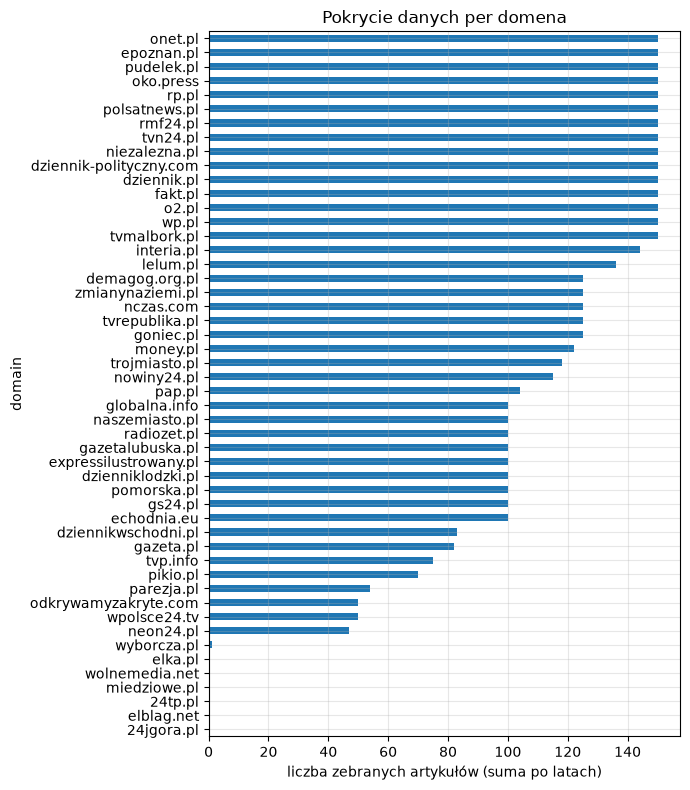

In [8]:
ax = coverage_pivot.sort_values("total")["total"].plot(kind="barh", figsize=(7, 8))
ax.set_xlabel("liczba zebranych artykułów (suma po latach)")
ax.set_title("Pokrycie danych per domena")
plt.tight_layout()
plt.show()


## 3. Podstawowe statystyki artykułów

Łączymy artykuły ze strata/rankiem Tranco i patrzymy na długość tekstu, obecność autora i wykrywanie języka.

In [12]:
articles = articles.merge(domains_frame[["domain", "stratum", "rank_tranco"]], on="domain", how="left", suffixes=("", "_frame"))
articles["stratum"] = articles["stratum_frame"].fillna(articles["stratum"])
articles = articles.drop(columns=["stratum_frame"])
articles[["domain", "stratum", "rank_tranco", "n_words", "author_present", "languages"]].describe(include="all")


,domain,stratum,rank_tranco,n_words,author_present,languages
count,5026,5026,3919.000000,5026.000000,5026,5026
unique,44,3,NaN,NaN,2,19
top,dziennik-polityczny.com,S2,NaN,NaN,True,pol
freq,150,2221,NaN,NaN,4687,4590
mean,NaN,NaN,80704.095177,533.654397,NaN,NaN
std,NaN,NaN,183155.485779,507.668012,NaN,NaN
min,NaN,NaN,809.000000,150.000000,NaN,NaN
25%,NaN,NaN,7213.000000,257.000000,NaN,NaN
50%,NaN,NaN,15633.000000,384.500000,NaN,NaN
75%,NaN,NaN,60888.000000,594.750000,NaN,NaN


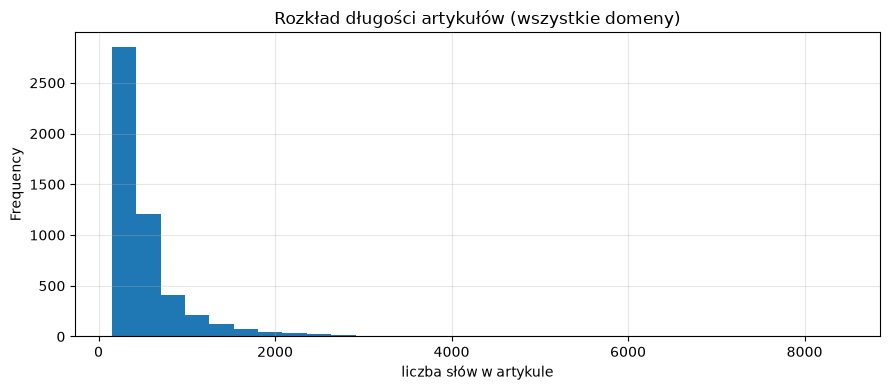

,count,mean,50%,min,max
stratum,,,,,
S1,1698.0,455.615430,342.0,150.0,4693.0
S2,2221.0,513.364701,378.0,150.0,8440.0
S3,1107.0,694.064137,465.0,151.0,4899.0


In [13]:
fig, ax = plt.subplots()
articles["n_words"].plot(kind="hist", bins=30, ax=ax)
ax.set_xlabel("liczba słów w artykule")
ax.set_title("Rozkład długości artykułów (wszystkie domeny)")
plt.tight_layout()
plt.show()

articles.groupby("stratum")["n_words"].describe()[["count", "mean", "50%", "min", "max"]]


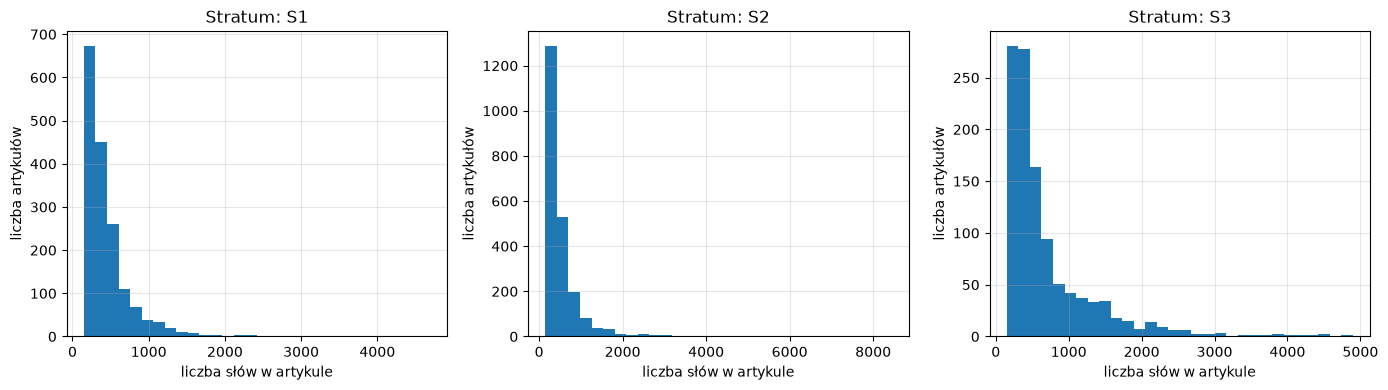

In [14]:
# 3 histograms for n_words each for each stratum:
strata = articles["stratum"].unique()
strata = sorted(strata, key=lambda s: int(s[1:]) if s.startswith("S") else float("inf"))
fig, axes = plt.subplots(1, len(strata), figsize=(14, 4))
for ax, stratum in zip(axes, strata):
    articles[articles["stratum"] == stratum]["n_words"].plot(kind="hist", bins=30, ax=ax)
    ax.set_title(f"Stratum: {stratum}")
    ax.set_xlabel("liczba słów w artykule")
    ax.set_ylabel("liczba artykułów")
plt.tight_layout()
plt.show()

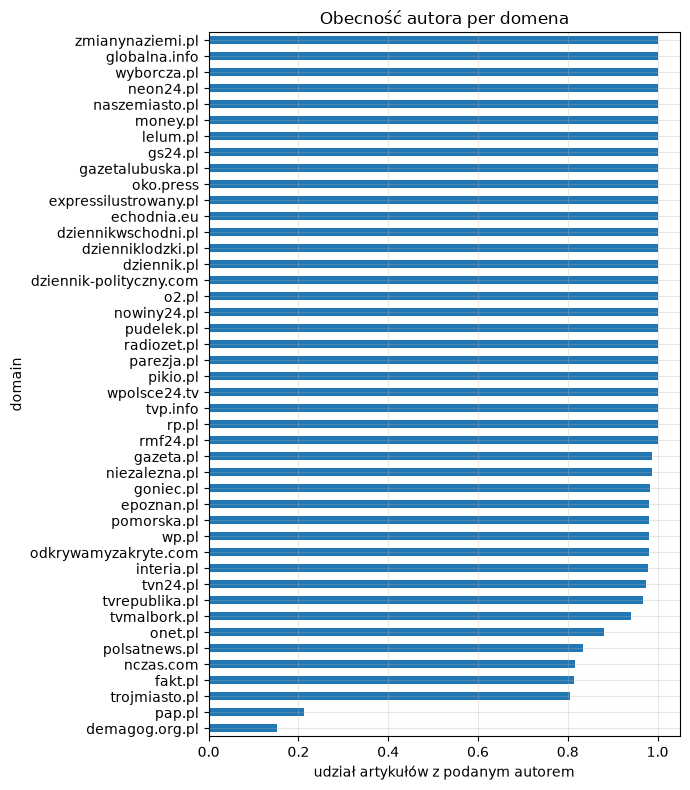

In [15]:
author_rate = articles.groupby("domain")["author_present"].mean().sort_values()
ax = author_rate.plot(kind="barh", figsize=(7, 8))
ax.set_xlabel("udział artykułów z podanym autorem")
ax.set_title("Obecność autora per domena")
plt.tight_layout()
plt.show()


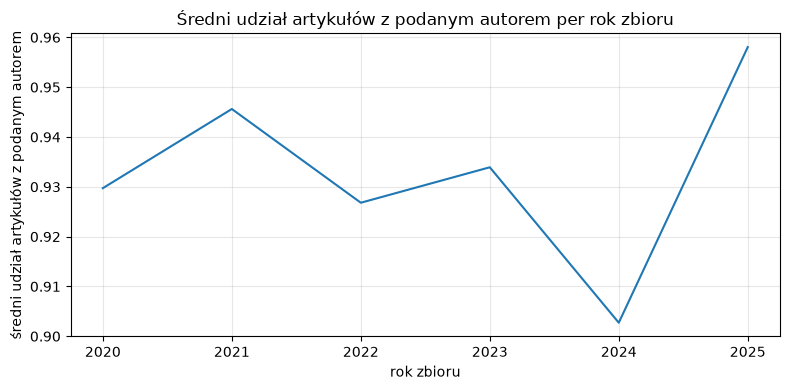

In [16]:
# wykres liczby autorów w czasie (z wszystkich artykułów, nie per domena):
author_counts = articles.groupby("collection_year_dir")["author_present"].mean()
ax = author_counts.plot(kind="line", figsize=(8, 4))
ax.set_xlabel("rok zbioru")
ax.set_ylabel("średni udział artykułów z podanym autorem")
ax.set_title("Średni udział artykułów z podanym autorem per rok zbioru")
plt.tight_layout()
plt.show()

In [17]:
lang_counts = articles["languages"].value_counts()
print(lang_counts)
non_pure_pol = articles[articles["languages"] != "pol"]
print(f"\nArtykuły z wykrytym więcej niż jednym językiem: {len(non_pure_pol)} / {len(articles)}")
non_pure_pol[["domain", "title", "languages"]]


languages
pol            4590
pol,eng         401
pol,deu           5
pol,rus           4
pol,jpn           4
pol,ita           3
pol,fra           3
pol,spa           3
pol,ukr           3
pol,eng,fra       1
pol,eng,spa       1
pol,hrv           1
pol,ita,eng       1
pol,hun           1
pol,slk           1
pol,deu,ita       1
pol,jpn,eng       1
pol,lat           1
pol,ind           1
Name: count, dtype: int64

Artykuły z wykrytym więcej niż jednym językiem: 436 / 5026


,domain,title,languages
6,demagog.org.pl,Ilu seniorów mieszka w Warszawie?,"pol,eng"
10,demagog.org.pl,Ile drzew rocznie sadzą Lasy Państwowe?,"pol,eng"
13,demagog.org.pl,Czy w Sejmie rozdawano posłom przeterminowane ...,"pol,eng"
63,dziennik.pl,Niemieckie media: Skoki przyćmione przez inter...,"pol,deu"
307,interia.pl,Liga angielska - 14. kolejka League Two: Exete...,"pol,eng"
...,...,...,...
4898,trojmiasto.pl,[Film czytelnika] Estakada Kwiatkowskiego Gdynia,"pol,eng"
4899,trojmiasto.pl,[Raport czytelnika] Gdańskie Morsy witają nowy...,"pol,eng"
4900,trojmiasto.pl,[Film czytelnika] Obwodnica południowa,"pol,eng"
4944,tvn24.pl,Rusza nieformalny szczyt w Paryżu. Macron przy...,"pol,eng"


## 4. Rozkład w czasie: `pub_date` vs `crawl_id`

Artykuły pochodzą z Common Crawl, który indeksuje strony z pewnym opóźnieniem względem publikacji — sprawdzamy,
czy `pub_date` faktycznie odpowiada deklarowanemu rokowi folderu i jak duży jest ten lag.

In [18]:
articles["pub_date"] = pd.to_datetime(articles["pub_date"], errors="coerce")
articles["pub_year_check"] = articles["pub_date"].dt.year

mismatch = articles[articles["pub_year_check"].astype("Int64") != articles["collection_year_dir"].astype(int)]
print(f"Artykuły, dla których pub_date nie zgadza się z folderem roku: {len(mismatch)} / {len(articles)}")
mismatch[["domain", "collection_year_dir", "pub_date", "crawl_id"]]


Artykuły, dla których pub_date nie zgadza się z folderem roku: 0 / 5026


,domain,collection_year_dir,pub_date,crawl_id


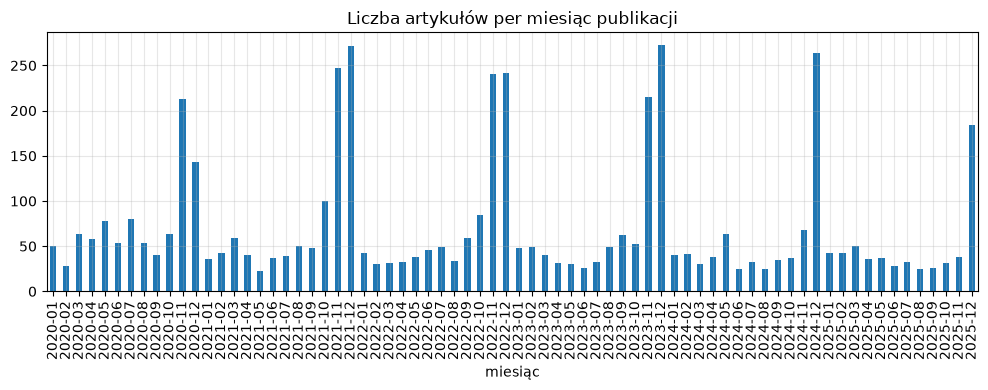

In [19]:
ax = articles["pub_date"].dt.to_period("M").value_counts().sort_index().plot(kind="bar", figsize=(10, 4))
ax.set_title("Liczba artykułów per miesiąc publikacji")
ax.set_xlabel("miesiąc")
plt.tight_layout()
plt.show()


## 5. Duplikaty i jakość tekstu

Sprawdzamy duplikaty treści (`text_sha1`) i krótkie artykuły

In [20]:
dup_counts = articles["text_sha1"].value_counts()
dups = dup_counts[dup_counts > 1]
print(f"Zduplikowanych treści (ten sam text_sha1 w >1 artykule): {len(dups)}")
articles[articles["text_sha1"].isin(dups.index)][["domain", "collection_year_dir", "title", "text_sha1"]].sort_values("text_sha1")


Zduplikowanych treści (ten sam text_sha1 w >1 artykule): 4


,domain,collection_year_dir,title,text_sha1
3413,onet.pl,2023,Jak zmniejszyć rachunki za pranie? Wystarczy z...,054e3e7de145c35817d4d714738dee3bd80aa330
4168,onet.pl,2024,Jak zmniejszyć rachunki za pranie? Wystarczy z...,054e3e7de145c35817d4d714738dee3bd80aa330
4324,tvmalbork.pl,2024,Kąty Rybackie pogoda na żywo. Wejście na plażę...,710c49d33c96fafd5f4bc458b1567c57f0fe5167
4921,tvmalbork.pl,2025,Kąty Rybackie pogoda na żywo. Wejście na plażę...,710c49d33c96fafd5f4bc458b1567c57f0fe5167
2321,naszemiasto.pl,2022,Ściąga przed grzybobraniem. Pod jakimi drzewam...,a53cad1276d92a80a11c5b9c2720f7622e00617e
2555,pomorska.pl,2022,Ściąga przed grzybobraniem. Pod jakimi drzewam...,a53cad1276d92a80a11c5b9c2720f7622e00617e
1773,tvmalbork.pl,2021,Zmarł Franciszek Szczyglewski. Żył 85 lat. | T...,d44cb4c75df5d079a50b29004e454f29807c3c2b
2699,tvmalbork.pl,2022,Przekop Mierzei Wiślanej: Jak będą odmulać ślu...,d44cb4c75df5d079a50b29004e454f29807c3c2b
3637,tvmalbork.pl,2023,Zmarł Zbigniew Majka. Żył 67 lat. | TvMalbork.pl,d44cb4c75df5d079a50b29004e454f29807c3c2b
4315,tvmalbork.pl,2024,Zmarła Irena Piwońska. Żyła 67 lat. | TvMalbor...,d44cb4c75df5d079a50b29004e454f29807c3c2b


In [21]:
short_articles = articles.sort_values("n_words").head(10)
short_articles[["domain", "collection_year_dir", "title", "n_words"]]


,domain,collection_year_dir,title,n_words
293,gs24.pl,2020,Rozbudowa Teatru Polskiego w Szczecinie. Znamy...,150
1772,tvmalbork.pl,2021,Przekop Mierzei Wiślanej. Utrudnienia i ruch w...,150
3861,epoznan.pl,2024,Duża akcja strażaków w szpitalu przy ulicy Szw...,150
4940,tvn24.pl,2025,Śmiertelne postrzelenie seniorki. Zatrzymany 9...,150
1716,rmf24.pl,2021,Małoletni złodzieje rowerów. Nie potrafili się...,150
4883,rp.pl,2025,Planujesz przejść na emeryturę w 2026 roku? Ek...,150
2228,gs24.pl,2022,Piłka nożna. Cukierek albo psikus? Robert Lewa...,150
1880,wp.pl,2021,Polska fitnesska długo na to czekała. Rzuciła ...,150
1694,rmf24.pl,2021,Specjaliści alarmują: Nie lekceważmy wariantu ...,150
676,pudelek.pl,2020,"Łukasz Darłak zagra w ""Na Wspólnej"". ""Cześć ws...",150


## 6. Wstępne sygnały stylometryczne (eksploracyjne, pod kątem AI)

Cechy:
- średnia długość zdania i słowa,
- bogactwo słownictwa (type-token ratio),
- liczba akapitów (`\n\n`),
- częstość wybranych fraz/znaków częściej kojarzonych z tekstem generowanym przez LLM po polsku
  (myślnik `—`, "podsumowując", "warto zauważyć", "należy zauważyć", "ponadto", "jednakże").

In [22]:
AI_MARKER_PATTERNS = {
    "em_dash": "—",
    "podsumowujac": r"podsumowuj\w*",
    "warto_zauwazyc": r"warto zauwa\w+",
    "nalezy_zauwazyc": r"nale\u017cy zauwa\w+",
    "ponadto": r"\bponadto\b",
    "jednakze": r"\bjednak\u017ce\b",
}


def text_stats(text: str) -> dict:
    words = re.findall(r"\b[\w\u0105\u0107\u0119\u0142\u0144\u00f3\u015b\u017a\u017c]+\b", text.lower())
    sentences = [s for s in re.split(r"[.!?]+", text) if s.strip()]
    n_words = max(len(words), 1)
    stats = {
        "avg_sentence_len_words": n_words / max(len(sentences), 1),
        "avg_word_len_chars": sum(len(w) for w in words) / n_words,
        "ttr": len(set(words)) / n_words,
        "n_paragraphs": text.count("\n\n") + 1,
    }
    for name, pattern in AI_MARKER_PATTERNS.items():
        stats[f"marker_{name}_per_1000w"] = 1000 * len(re.findall(pattern, text, flags=re.IGNORECASE)) / n_words
    return stats


style_df = pd.DataFrame(articles["text"].apply(text_stats).tolist(), index=articles.index)
articles_style = pd.concat([articles[["domain", "stratum", "collection_year_dir"]], style_df], axis=1)
articles_style.groupby("domain").mean(numeric_only=True).round(3)


,avg_sentence_len_words,avg_word_len_chars,ttr,n_paragraphs,marker_em_dash_per_1000w,marker_podsumowujac_per_1000w,marker_warto_zauwazyc_per_1000w,marker_nalezy_zauwazyc_per_1000w,marker_ponadto_per_1000w,marker_jednakze_per_1000w
domain,,,,,,,,,,
demagog.org.pl,14.169,5.960,0.536,1.0,0.320,0.074,0.018,0.000,0.223,0.089
dziennik-polityczny.com,13.969,5.955,0.643,1.0,2.060,0.091,0.035,0.021,0.166,0.019
dziennik.pl,14.494,5.754,0.671,1.0,0.062,0.074,0.019,0.000,0.155,0.000
dzienniklodzki.pl,14.270,5.692,0.650,1.0,0.070,0.091,0.000,0.000,0.182,0.028
dziennikwschodni.pl,13.690,5.748,0.657,1.0,0.000,0.090,0.000,0.000,0.167,0.000
echodnia.eu,14.442,5.910,0.656,1.0,0.039,0.061,0.000,0.000,0.181,0.020
epoznan.pl,12.750,5.941,0.698,1.0,0.107,0.027,0.000,0.000,0.248,0.000
expressilustrowany.pl,13.611,5.660,0.651,1.0,0.000,0.017,0.000,0.000,0.171,0.000
fakt.pl,10.406,5.676,0.611,1.0,3.688,0.020,0.000,0.000,0.035,0.000


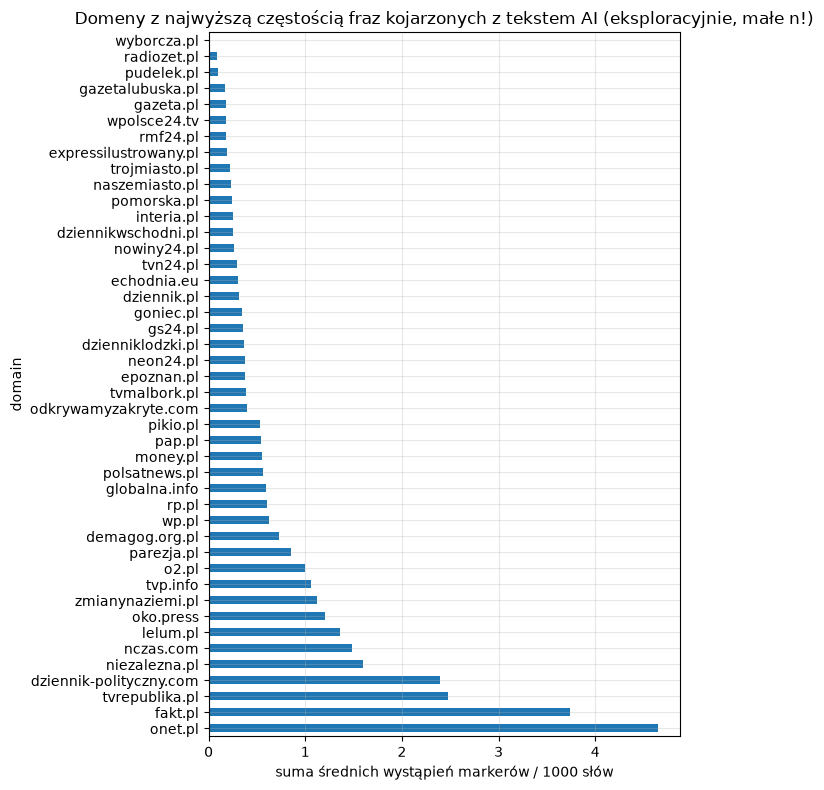

In [23]:
marker_cols = [c for c in articles_style.columns if c.startswith("marker_")]
marker_totals = articles_style.groupby("domain")[marker_cols].mean().sum(axis=1).sort_values(ascending=False)

ax = marker_totals.plot(kind="barh", figsize=(7, 8))
ax.set_xlabel("suma średnich wystąpień markerów / 1000 słów")
ax.set_title("Domeny z najwyższą częstością fraz kojarzonych z tekstem AI (eksploracyjnie, małe n!)")
plt.tight_layout()
plt.show()


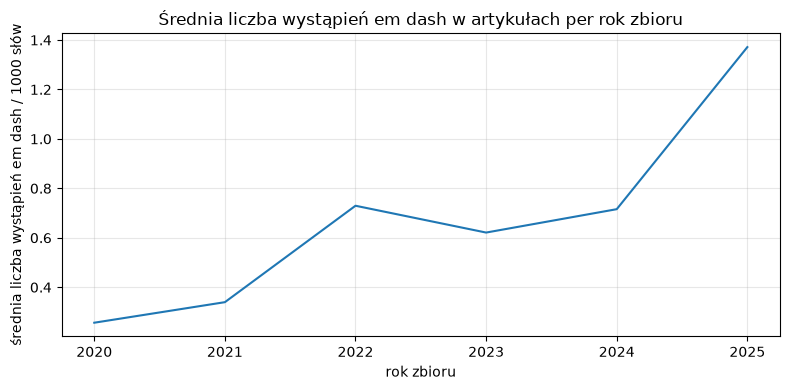

In [24]:
# em dash count in time (from all the articles, not per domain) as a plot:
em_dash_counts = articles_style.groupby("collection_year_dir")["marker_em_dash_per_1000w"].mean()
ax = em_dash_counts.plot(kind="line", figsize=(8, 4))
ax.set_xlabel("rok zbioru")
ax.set_ylabel("średnia liczba wystąpień em dash / 1000 słów")
ax.set_title("Średnia liczba wystąpień em dash w artykułach per rok zbioru")
plt.tight_layout()
plt.show()


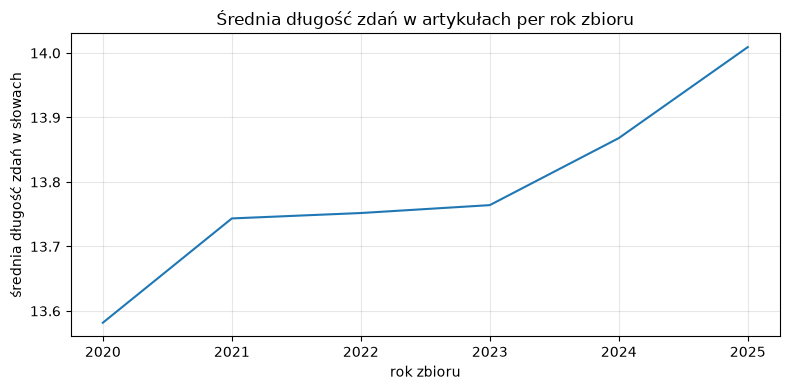

In [25]:
# wykres ze średnią długością zdań w czasie (z wszystkich artykułów, nie per domena):
avg_sentence_len = articles_style.groupby("collection_year_dir")["avg_sentence_len_words"].mean()
ax = avg_sentence_len.plot(kind="line", figsize=(8, 4))
ax.set_xlabel("rok zbioru")
ax.set_ylabel("średnia długość zdań w słowach")
ax.set_title("Średnia długość zdań w artykułach per rok zbioru")
plt.tight_layout()
plt.show()

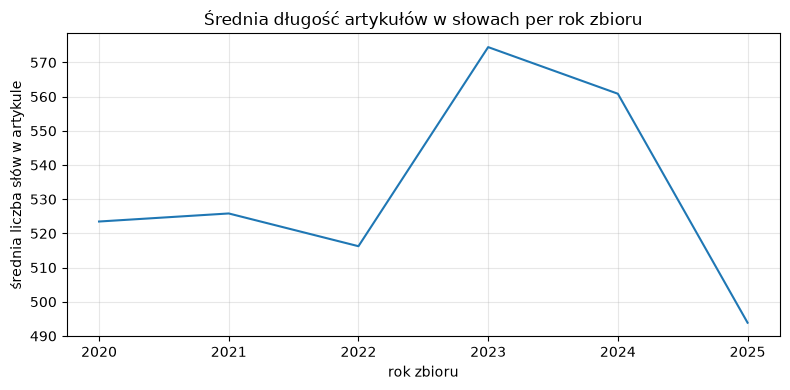

In [26]:
# wykres ze średnią dgością artykułów w czasie (z wszystkich artykułów, nie per domena):
avg_n_words = articles.groupby("collection_year_dir")["n_words"].mean()
ax = avg_n_words.plot(kind="line", figsize=(8, 4))
ax.set_xlabel("rok zbioru")
ax.set_ylabel("średnia liczba słów w artykule")
ax.set_title("Średnia długość artykułów w słowach per rok zbioru")
plt.tight_layout()
plt.show()

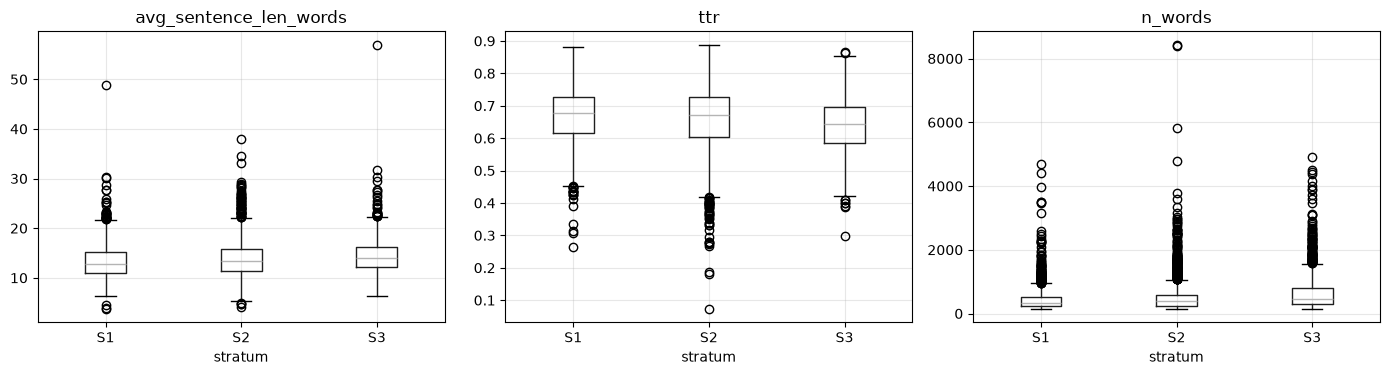

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["avg_sentence_len_words", "ttr", "n_words"]):
    if ax==axes[2]:
        articles.boxplot(column="n_words", by="stratum", ax=ax)
        ax.set_title("n_words")
        ax.set_xlabel("stratum")
    else:
        articles_style.boxplot(column=col, by="stratum", ax=ax)
        ax.set_title(col)
        ax.set_xlabel("stratum")
plt.suptitle("")
plt.tight_layout()
plt.show()
